Phần A — Nền tảng Matplotlib

In [ ]:
# Ô 1 — Thiết lập
import sys
from pathlib import Path

sys.path.append(str(Path("..").resolve()))

import pandas as pd
import matplotlib.pyplot as plt # thư viện vẽ gốc
import seaborn as sns # lớp tiện ích xây trên Matplotlib, vẽ thẳng từ DataFrame với ít code hơn.
from src.clean import load_events, clean_events

RAW = Path("..") / "data" / "raw"
FIG = Path("..") / "figures"
FIG.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")

ev = clean_events(load_events(RAW / "evtx_data.csv"))
print(ev.shape)   # (4633, 16)

(4633, 16)


Figure Axes


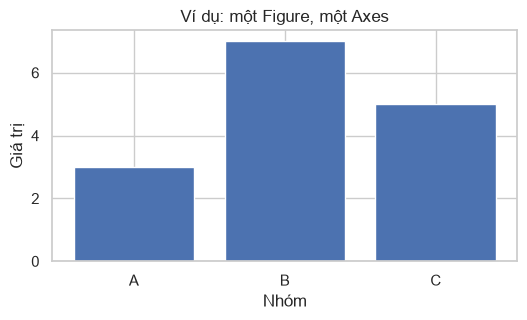

In [ ]:
# Ô 2 — Figure và Axes
fig, ax = plt.subplots(figsize=(6, 3)) # : tạo cùng lúc hai đối tượng (figsize=(6, 3): rộng 6, cao 3, đơn vị inch.)
# fig (Figure): cả khung ảnh, giống tờ giấy. Lưu ảnh và đặt kích thước làm ở đây
# ax (Axes): một ô biểu đồ nằm trên tờ giấy, gồm trục, cột, tiêu đề.
ax.bar(["A","B","C"],[3,7,5]) # ax.bar(nhãn, giá_trị): vẽ biểu đồ cột lên ô ax
ax.set_title("Ví dụ: một Figure, một Axes")
ax.set_xlabel("Nhóm")
ax.set_ylabel("Giá trị")
print(type(fig).__name__,type(ax).__name__)
plt.show() # hiển thị biểu đồ dưới ô

ndarray (2,)


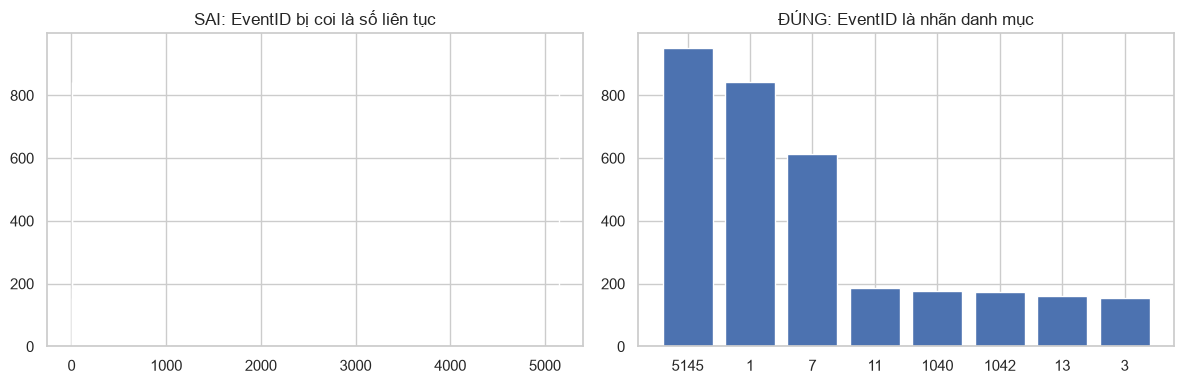

In [ ]:
# Ô 3 — Bẫy thường gặp: EventID bị coi là số

top = ev["EventID"].value_counts().head(8)
# print(top)

fig, axes = plt.subplots(1, 2, figsize=(12, 4)) # tạo 1 hàng, 2 cột ô biểu đồ
# Lúc này axes là một mảng chứa 2 Axes, truy cập bằng axes[0] và axes[1].
print(type(axes).__name__,axes.shape)

axes[0].bar(top.index,top.values) # top.index: các EventID (5145, 1, 7...). top.values: số đếm tương ứng.
axes[0].set_title("SAI: EventID bị coi là số liên tục")

axes[1].bar(top.index.astype(str), top.values)
axes[1].set_title("ĐÚNG: EventID là nhãn danh mục")

fig.tight_layout() # tự căn khoảng cách để tiêu đề và nhãn không đè lên nhau.
plt.show()
# EventID là mã (giống mã sản phẩm), không phải đại lượng đo

Phần B — Ba biểu đồ bắt buộc

                                Channel  EventID    n          label
0                              Security     5145  950  Security 5145
1  Microsoft-Windows-Sysmon/Operational        1  841       Sysmon 1
2  Microsoft-Windows-Sysmon/Operational        7  613       Sysmon 7


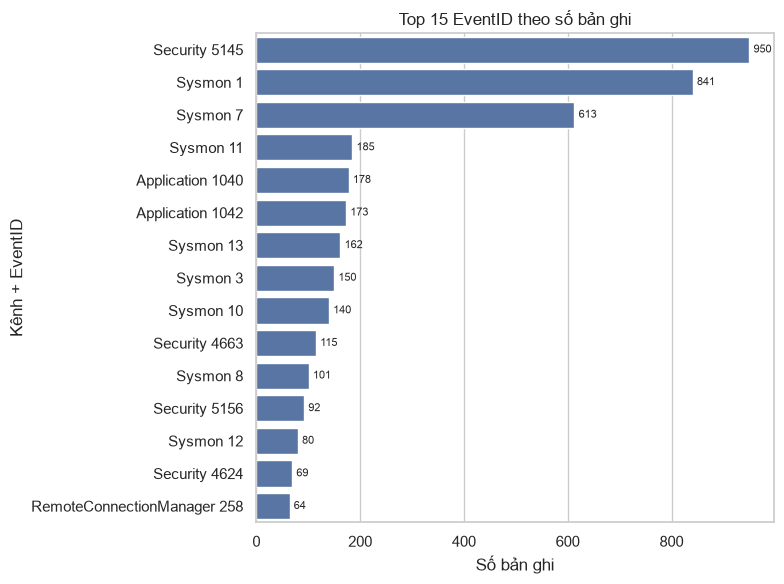

In [14]:
# Ô 4 — Biểu đồ 1: Phân bố EventID
def short_channel(ch) : 
  return ch.split("/")[0].split("-")[-1]

top = (ev.groupby(["Channel", "EventID"],observed=True)
        .size()
        .sort_values(ascending=False)
        .head(15)
        .reset_index(name="n"))

# .map áp hàm lên từng giá trị của cột
top["label"] = top["Channel"].astype(str).map(short_channel) + " " + top["EventID"].astype(str)
print(top.head(3))

fig,ax = plt.subplots(figsize=(8,6))
# sns.barplot(data=top, y="label", x="n", ax=ax, ...)
# data=top: bảng nguồn.
# y="label", x="n": nhãn đặt trên trục dọc nên ra cột ngang, giúp nhãn dài không bị chéo.
# ax=ax: vẽ lên ô đã tạo sẵn, để còn chỉnh tiếp bằng ax.set.
sns.barplot(data=top,y="label",x="n", ax=ax, color="#4C72B0")
# ax.set(title=..., xlabel=..., ylabel=...): đặt cả ba trong một lệnh, gọn hơn ba lệnh riêng.
ax.set(title="Top 15 EventID theo số bản ghi",
        xlabel="Số bản ghi", ylabel="Kênh + EventID")
# ax.bar_label(ax.containers[0], ...): ghi số lên đầu mỗi cột. ax.containers[0] là nhóm cột vừa vẽ. padding=3 để chữ cách đầu cột 3 điểm.
ax.bar_label(ax.containers[0],padding=3,fontsize=8)
fig.tight_layout();
fig.savefig(FIG / "01_eventid.png", dpi=150)
plt.show()


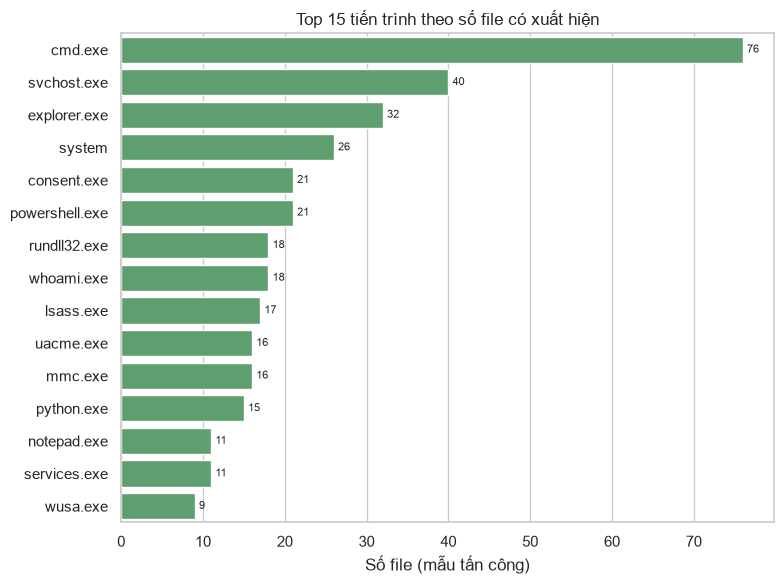

In [ ]:
# Ô 5 — Biểu đồ 2: Top tiến trình theo số file
pf =  (ev.dropna(subset=["process_name"])
        .groupby("process_name")["EVTX_FileName"].nunique()
        .sort_values(ascending=False)
        .head(15)
        .reset_index(name="n_files")
       )

fig,ax = plt.subplots(figsize=(8,6))
sns.barplot(data=pf,y="process_name",x="n_files", ax=ax , color="#55A868")
ax.set(title="Top 15 tiến trình theo số file có xuất hiện",xlabel="Số file (mẫu tấn công)", ylabel="")
ax.bar_label(ax.containers[0],padding=3,fontsize=8)
fig.tight_layout();
fig.savefig(FIG / "02.process.png", dpi=150) # số điểm ảnh (pixel) trên mỗi inch
plt.show()

['Privilege Escalation', 'Lateral Movement', 'Defense Evasion', 'Credential Access', 'Execution', 'Persistence', 'Discovery', 'Command and Control']
                                         EVTX_FileName                tactic
0    4624 LT3 AnonymousLogon Localhost - JuicyPotat...  Privilege Escalation
1                       4765_sidhistory_add_t1178.evtx  Privilege Escalation
2                 4794_DSRM_password_change_t1098.evtx     Credential Access
3      ACL_ForcePwd_SPNAdd_User_Computer_Accounts.evtx     Credential Access
4        CA_4624_4625_LogonType2_LogonProc_chrome.evtx     Credential Access
..                                                 ...                   ...
244          tunna_iis_rdp_smb_tunneling_sysmon_3.evtx   Command and Control
245           win10_4703_SeDebugPrivilege_enabled.evtx  Privilege Escalation
246  windows_bits_4_59_60_lolbas desktopimgdownldr....             Execution
247                    wmi_remote_registry_sysmon.evtx      Lateral Movement
248 

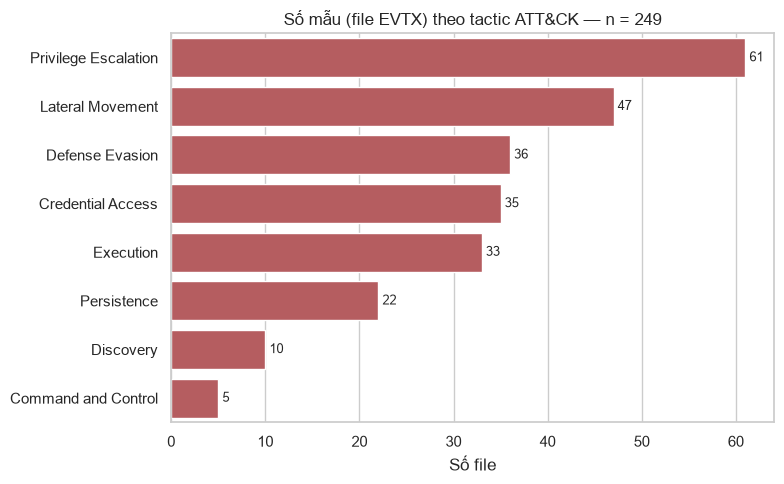

In [26]:
# Ô 6 — Biểu đồ 3: Số mẫu theo tactic
files = (ev.groupby("EVTX_FileName")
         .agg(tactic=("EVTX_Tactic","first"))
         .reset_index())

files["tactic"] = files["tactic"].astype(str)

# files["tactic"].value_counts() đếm mỗi tactic có bao nhiêu file, sắp giảm dần:
# .index chỉ lấy phần nhãn bên trái (tên tactic), bỏ phần số đếm:
order = files["tactic"].value_counts().index # danh sách tactic sắp theo số file giảm dần, dùng làm thứ tự vẽ.
print(list(order))

print(files)

fig, ax = plt.subplots(figsize=(8 , 5))
# ép thứ tự cột theo danh sách đã sắp.
sns.countplot(data=files, y="tactic", order=order, ax=ax, color="#C44E52")
ax.set(title=f"Số mẫu (file EVTX) theo tactic ATT&CK — n = {len(files)}",
       xlabel="Số file", ylabel="")
ax.bar_label(ax.containers[0], padding=3, fontsize=9)
fig.tight_layout()
fig.savefig(FIG / "03_tactic.png", dpi=150)
plt.show()


Phần C — So sánh và bài tập

                      Số bản ghi  Số file
Command and Control          432        5
Discovery                    167       10
Persistence                  411       22
Execution                    533       33
Credential Access            283       35
Defense Evasion              431       36
Lateral Movement            1288       47
Privilege Escalation        1088       61


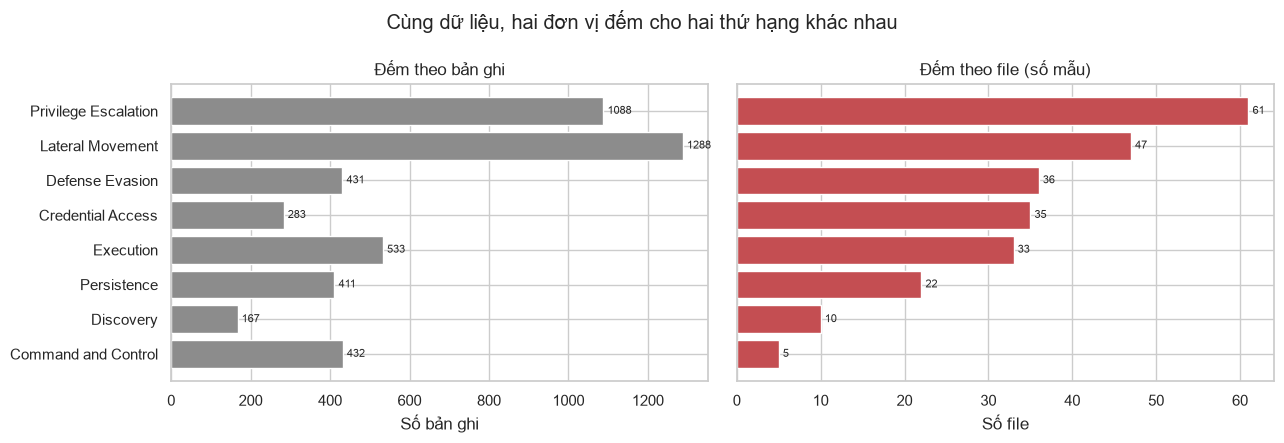

In [27]:
# Ô 7 — Cùng dữ liệu, hai đơn vị đếm
rec = ev["EVTX_Tactic"].astype(str).value_counts()
fil = files["tactic"].value_counts()

cmp = (pd.DataFrame({"Số bản ghi": rec, "Số file": fil})
         .sort_values("Số file", ascending=True))
print(cmp)
#                       Số bản ghi  Số file
# Command and Control          432        5
# Discovery                    167       10
# ...
# Privilege Escalation        1088       61

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
axes[0].barh(cmp.index, cmp["Số bản ghi"], color="#8C8C8C")
axes[0].set(title="Đếm theo bản ghi", xlabel="Số bản ghi")
axes[1].barh(cmp.index, cmp["Số file"], color="#C44E52")
axes[1].set(title="Đếm theo file (số mẫu)", xlabel="Số file")
for a in axes:
    a.bar_label(a.containers[0], padding=3, fontsize=8)
fig.suptitle("Cùng dữ liệu, hai đơn vị đếm cho hai thứ hạng khác nhau")
fig.tight_layout()
fig.savefig(FIG / "04_unit_compare.png", dpi=120)
plt.show()

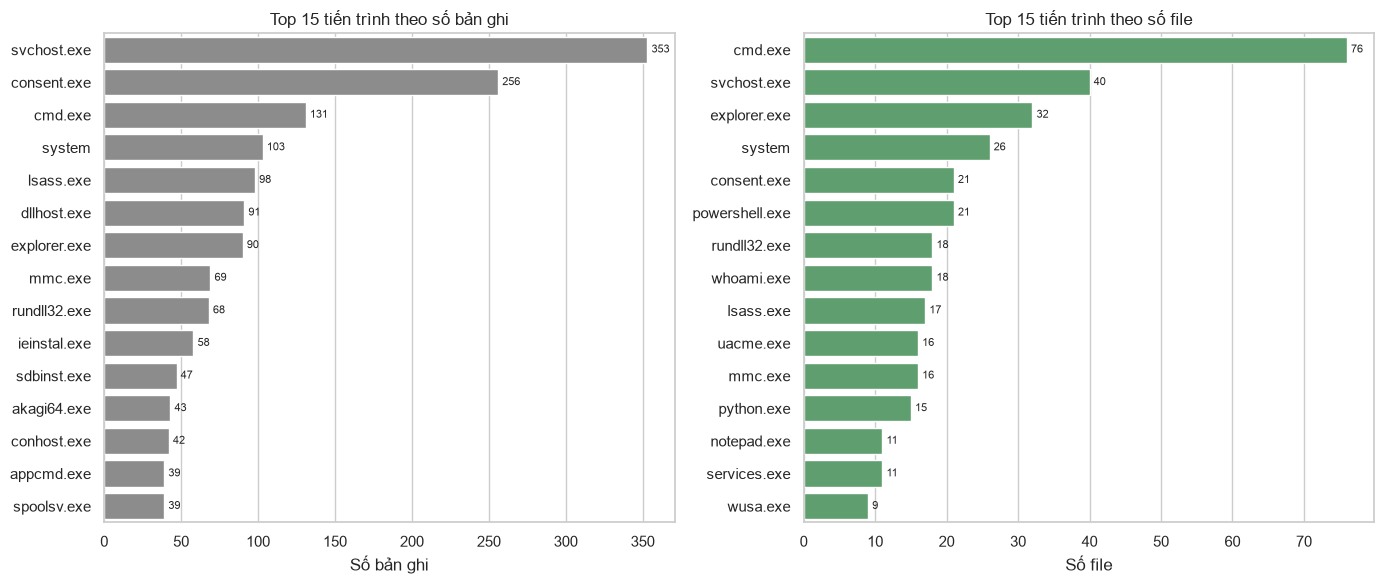

In [29]:
# Ô 8 — Bài tập 2: Top tiến trình theo hai cách, đặt cạnh nhau
pr = ev["process_name"].value_counts().head(15).reset_index()
pr.columns = ["process_name", "n_events"]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(data=pr, y="process_name", x="n_events", ax=axes[0], color="#8C8C8C")
axes[0].set(title="Top 15 tiến trình theo số bản ghi", xlabel="Số bản ghi", ylabel="")

sns.barplot(data=pf, y="process_name", x="n_files", ax=axes[1], color="#55A868")
axes[1].set(title="Top 15 tiến trình theo số file", xlabel="Số file", ylabel="")

for a in axes:
    a.bar_label(a.containers[0], padding=3, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "05_process_compare.png", dpi=110)
plt.show()

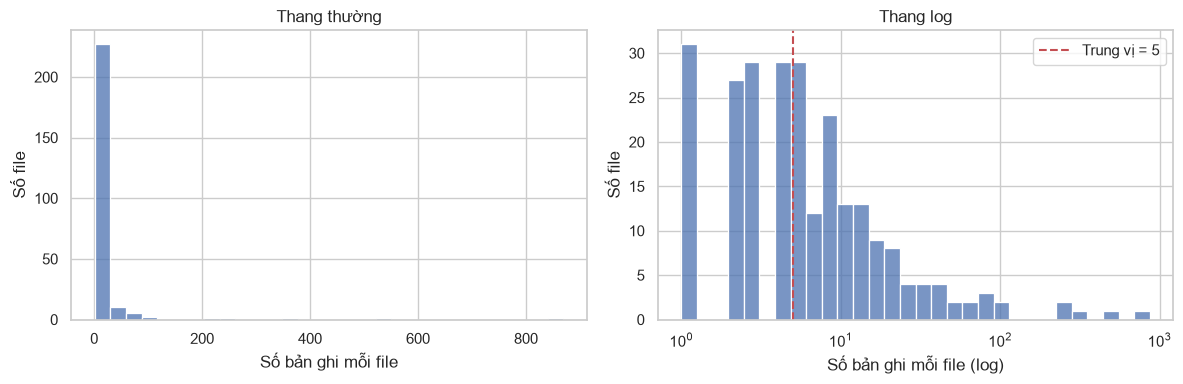

In [30]:
# Ô 9 — Histogram: phân bố số bản ghi mỗi file
s = ev.groupby("EVTX_FileName").size()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(s, bins=30, ax=axes[0])
axes[0].set(title="Thang thường", xlabel="Số bản ghi mỗi file", ylabel="Số file")

sns.histplot(s, bins=30, log_scale=True, ax=axes[1])
axes[1].set(title="Thang log", xlabel="Số bản ghi mỗi file (log)", ylabel="Số file")
axes[1].axvline(s.median(), color="#C44E52", linestyle="--",
                label=f"Trung vị = {s.median():.0f}")
axes[1].legend()

fig.tight_layout()
fig.savefig(FIG / "06_hist.png", dpi=110)
plt.show()

(8, 10)


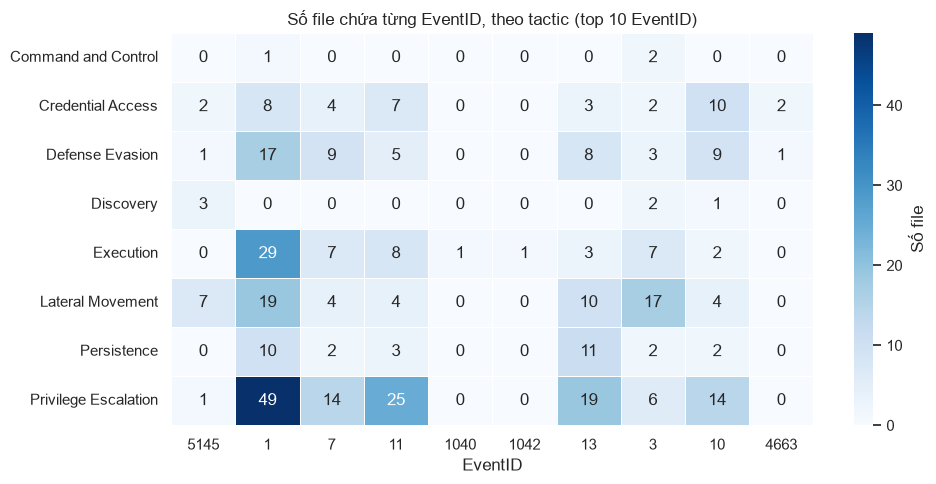

In [31]:
# Ô 10 — Heatmap: tactic × EventID, đếm theo file
top_ids = ev["EventID"].value_counts().head(10).index

hm = (ev[ev["EventID"].isin(top_ids)]
        .pivot_table(index="EVTX_Tactic", columns="EventID",
                     values="EVTX_FileName", aggfunc="nunique",
                     fill_value=0, observed=True))
hm = hm[top_ids]
print(hm.shape)   # (8, 10)

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(hm, annot=True, fmt="d", cmap="Blues", linewidths=0.5,
            cbar_kws={"label": "Số file"}, ax=ax)
ax.set(title="Số file chứa từng EventID, theo tactic (top 10 EventID)",
       xlabel="EventID", ylabel="")
fig.tight_layout()
fig.savefig(FIG / "07_heatmap.png", dpi=110)
plt.show()

In [ ]:
# Ô 11 — Kiểm tra các ảnh đã lưu
sorted(p.name for p in FIG.iterdir())
# ['01_eventid.png', '02_process.png', '03_tactic.png', '04_unit_compare.png',
#  '05_process_compare.png', '06_hist.png', '07_heatmap.png']